# Frozen held-out RAG evaluation: offline analysis

Compare four workflows on **40 questions across eight documentation families**, with three fresh repeats per question. Recompute from the published traces, original judgments, source-bound AI adjudications and physical API receipts. This notebook makes **no model calls** and does not change the frozen scientific inputs.

**Audience:** project reviewers and contributors. **Success criteria:** verify all 480 trace identities, recompute 40 paired questions, retain seven execution failures and unknown charges, export three figure sets and auditable tables.

The protocol, comparison and sample were frozen before generation. This notebook and source-review explanations were written after the results were available. AI-authored references and AI scoring have **zero independent human validations**.


## 1. Environment and saved inputs

Install the project dependencies and `output/jupyter-notebook/analysis-requirements.txt` using Python 3.11. Run from the repository root or this notebook's directory. The runner selects its own Python interpreter and starts a fresh kernel. Python socket connections are blocked below; installation is a separate online step.


In [1]:
from pathlib import Path
import importlib.metadata
import socket
import sys

def deny_network(*args, **kwargs):
    raise RuntimeError("Offline analysis: network connections are disabled")

socket.create_connection = deny_network
socket.socket.connect = deny_network
socket.socket.connect_ex = deny_network
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "docs/evaluation/heldout-test/reviewed-analysis.json").is_file())
sys.path.insert(0, str(ROOT / "docs/evaluation/heldout-test/tools"))
from notebook_analysis import load_packet, recompute_tables, write_tables, render_figures
from verify_reviewed import verify
print("Python:", sys.version.split()[0])
for name in ("numpy", "pydantic", "fastapi", "openai", "langgraph", "matplotlib", "nbformat", "nbclient"):
    print(f"{name}: {importlib.metadata.version(name)}")


Python: 3.11.9
numpy: 1.26.4
pydantic: 2.8.2
fastapi: 0.112.2
openai: 1.43.0
langgraph: 0.2.18
matplotlib: 3.9.4
nbformat: 5.10.4
nbclient: 0.10.2


## 2. Integrity before aggregation

The existing verifier checks the frozen inputs, byte hashes, execution ordering, all original judgments, source decisions, every request's trace assignment, available prices and the prespecified family bootstrap. The initial analysis remains intact.


In [2]:
verify()
summary, analysis, cases, traces, receipts = load_packet()
tables = recompute_tables(summary, analysis, cases, traces, receipts)
print(f"Executed: {len(traces)}; successful: {sum(t.status == 'success' for t in traces.values())}; failed: {sum(t.status != 'success' for t in traces.values())}")
print(f"Missing successful-answer judgments: {len(summary['missing_successful_judgments'])}; independent human scores: {tables['human_answer_scores']}")


Reviewed packet PASS: 480 traces, 80 sampled + 17 additional AI reviews, 3960 physical receipts; original judges, hashes, scores and 40 paired questions recompute. Human scoring: 0.
Executed: 480; successful: 473; failed: 7
Missing successful-answer judgments: 0; independent human scores: 0


## 3. Quality, latency and workload

Primary quality averages three repeats within each question, **including execution-failure zeros**, and then averages 40 question means. Latency is conditional on successful execution. Physical answer attempts include query embeddings and retries; they exclude shared index construction, original judging and source review.

Plain RAG has the highest observed primary quality here. Multi-agent versus single-agent is the prespecified comparison. These are distinct findings.


In [3]:
print(f"{'Workflow':<22} {'Quality':>8} {'Success':>9} {'Median sec':>11} {'Attempts':>9}")
for row in tables['variants']:
    print(f"{row['variant']:<22} {row['quality']:8.3f} {row['successful']:>5}/120 {row['median_success_seconds']:11.3f} {row['answer_attempts']:9}")


Workflow                Quality   Success  Median sec  Attempts
baseline_llm              0.643   120/120       5.961       120
llm_rag                   0.919   119/120       3.973       248
single_agent_rag          0.821   119/120       8.646       815
multi_agent_rag           0.878   115/120      49.848      2070


## 4. Paired uncertainty and review sensitivity

The frozen primary statistic is multi-agent minus single-agent correctness. Repeats are averaged within each question; 10,000 bootstrap draws resample the **eight document families**, with seed 20261023. The notebook verifies the frozen implementation instead of replacing it with an answer-level bootstrap.

Source review followed the initial aggregate analysis. The same DeepSeek alias supplied the initial judgments and source proposals in separate contexts, with explicit Codex follow-ups. The change from the initial estimate must remain visible; it is not an independent-model replication.


In [4]:
for name, result in [('Initial (retained)', summary['initial_primary']), ('Source-reviewed', tables['primary'])]:
    lo, hi = result['family_bootstrap_95_interval']
    print(f"{name}: {result['complete_pairs']}/40 pairs; difference {result['mean_paired_correctness_difference']*100:+.2f} pp; 95% interval [{lo*100:+.2f}, {hi*100:+.2f}] pp")
print(f"Source checks: {summary['source_adjudications']} answers + {summary['source_failure_audits']} failures; Codex follow-ups: {summary['codex_followups']}")


Initial (retained): 34/40 pairs; difference +4.25 pp; 95% interval [-0.35, +8.25] pp
Source-reviewed: 40/40 pairs; difference +5.69 pp; 95% interval [+1.39, +9.72] pp
Source checks: 90 answers + 7 failures; Codex follow-ups: 37


## 5. Request accounting and unknown charges

Keep indexing, answers, original judging and source review separate. Unknown token usage and unverified DeepSeek account prices stay **null**, never zero. The paired answer-cost estimate has only 30/40 complete question pairs and excludes indexing and judging/review. It is an API price estimate, not an invoice or a complete project bill.


In [5]:
for phase, count in tables['phase_attempts'].items():
    print(f"{phase:<22} {count:>5} physical attempts")
usage = tables['recorded_usage']
print(f"Total: {usage['physical_attempts']}; unknown-usage attempts: {usage['unknown_usage_attempts']}; total CNY: {usage['estimated_cost_cny']}")
cost = tables['incremental_answer_cost']
print(f"Incremental multi-minus-single answer cost: CNY {float(cost['mean_difference_cny']):.6f}, {cost['complete_pairs']}/40 complete question pairs")
print('Cost 95% family interval:', cost['family_bootstrap_95_interval'])


answer_generation       3253 physical attempts
blinded_judging          500 physical attempts
index_setup               90 physical attempts
source_review            117 physical attempts
Total: 3960; unknown-usage attempts: 17; total CNY: None
Incremental multi-minus-single answer cost: CNY 0.004722, 30/40 complete question pairs
Cost 95% family interval: [0.004016782142857143, 0.005457695498768473]


## 6. Recompute figures and portable tables

Export PNG for reading, SVG for sharing, PDF to the local artifacts directory, JSON for precise plotted values, and CSV containing all 160 question-by-workflow means. Conditional citation metrics show their individual denominators. No confidence intervals are invented for the four workflow means; the prespecified interval appears only on the primary paired comparison.


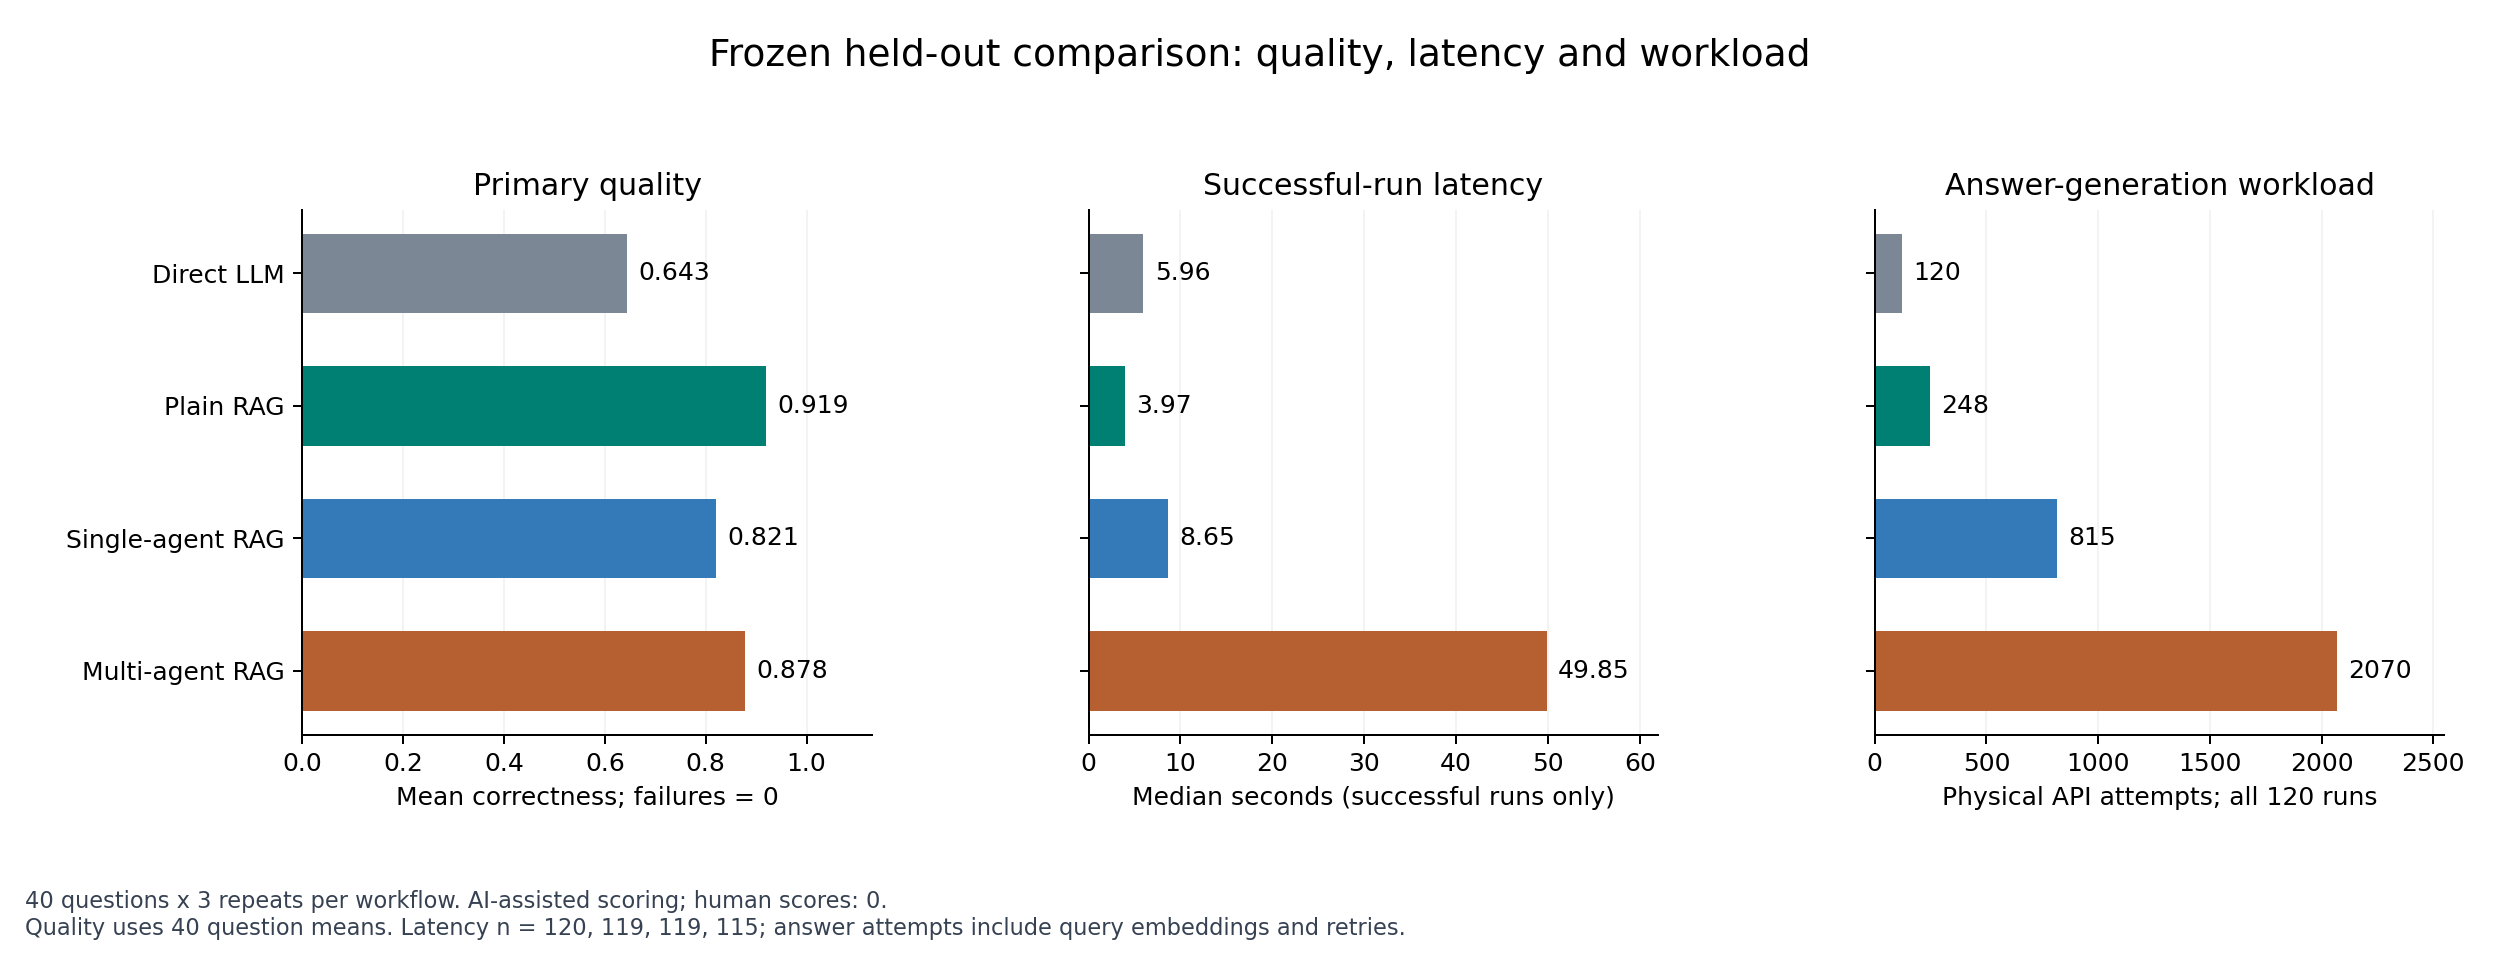

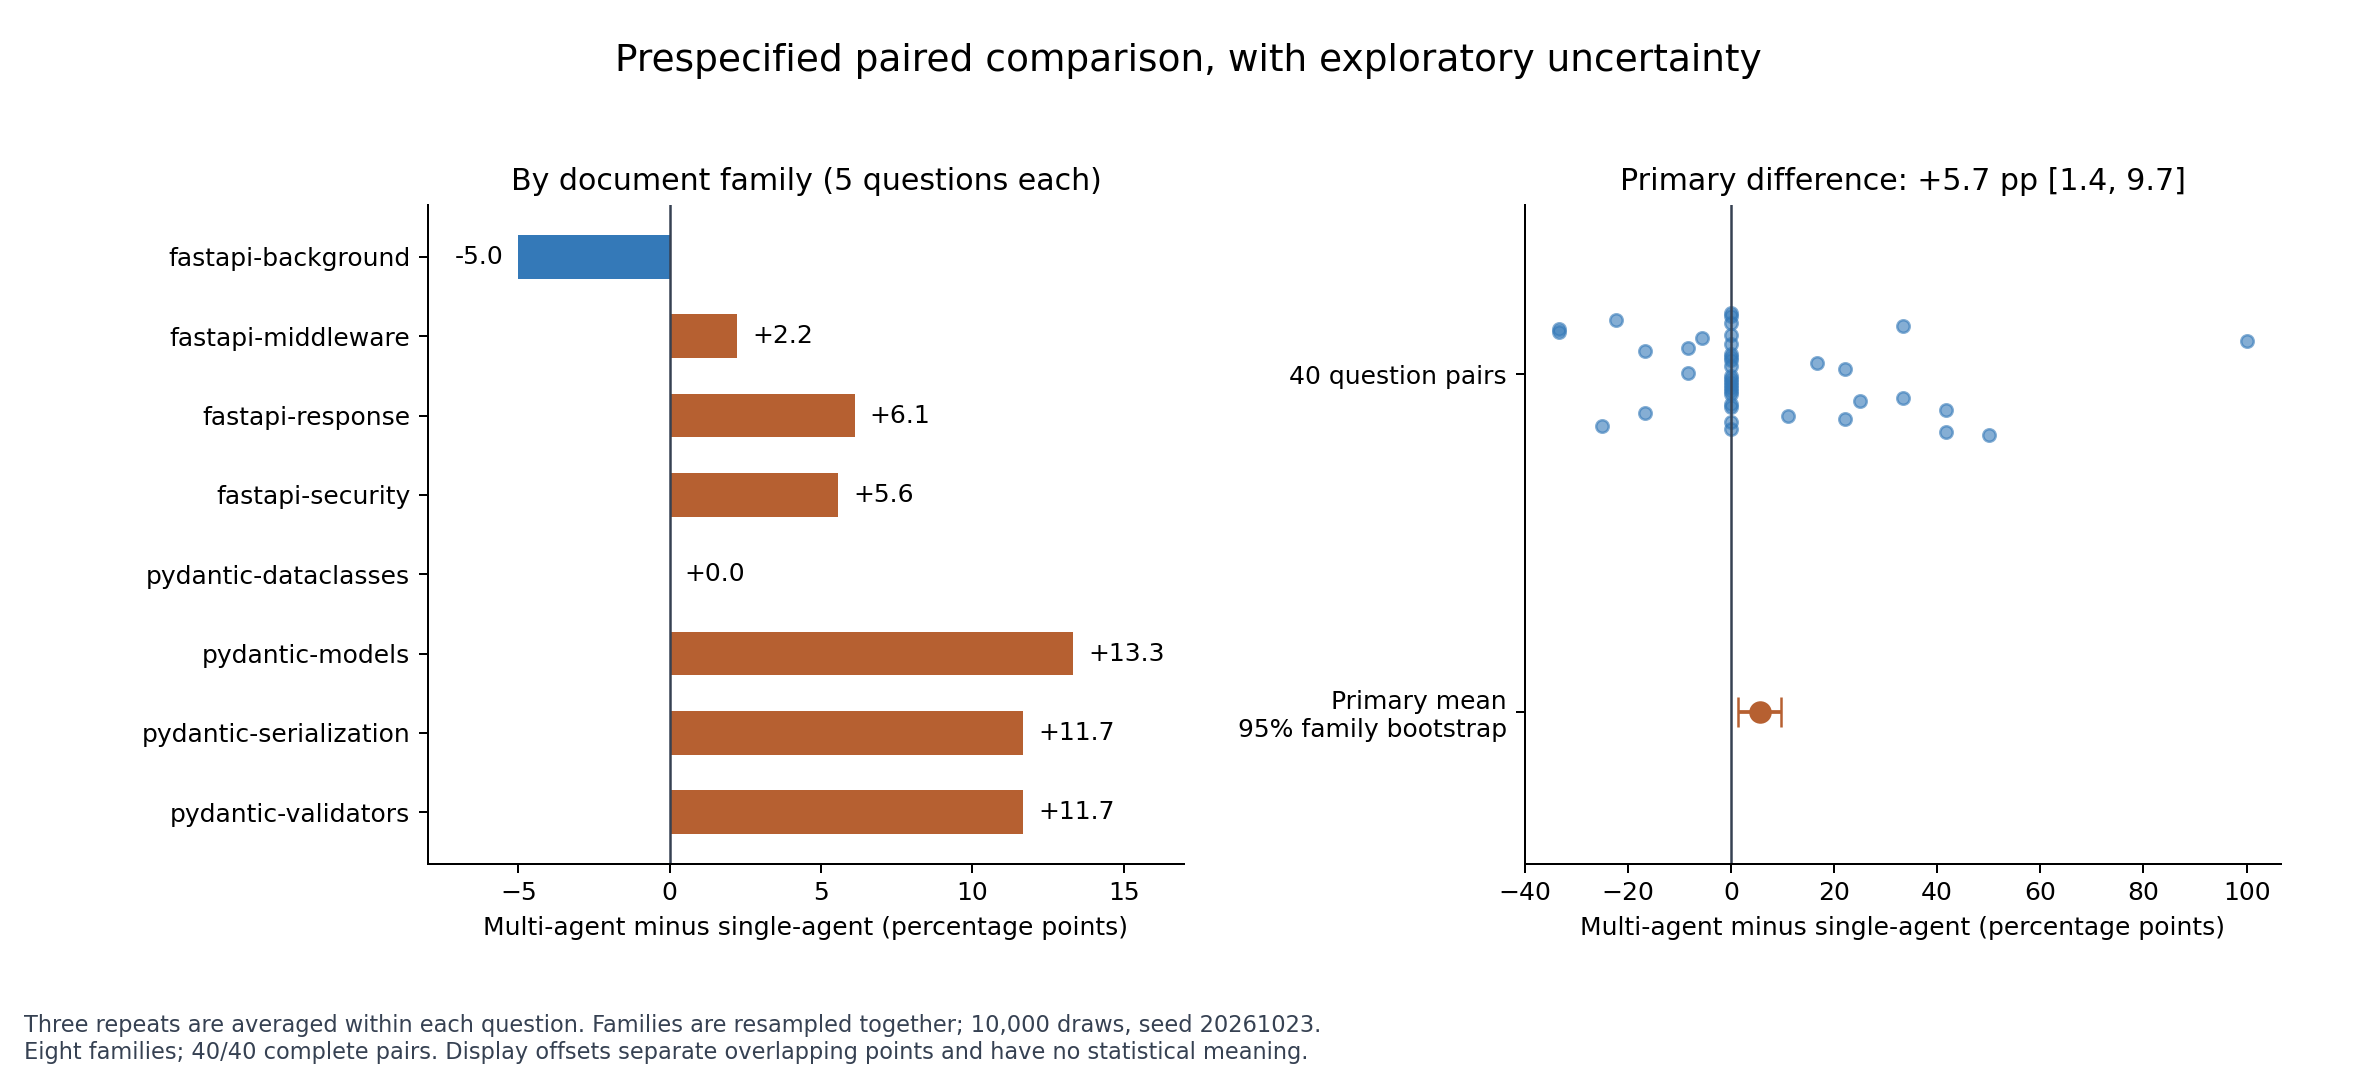

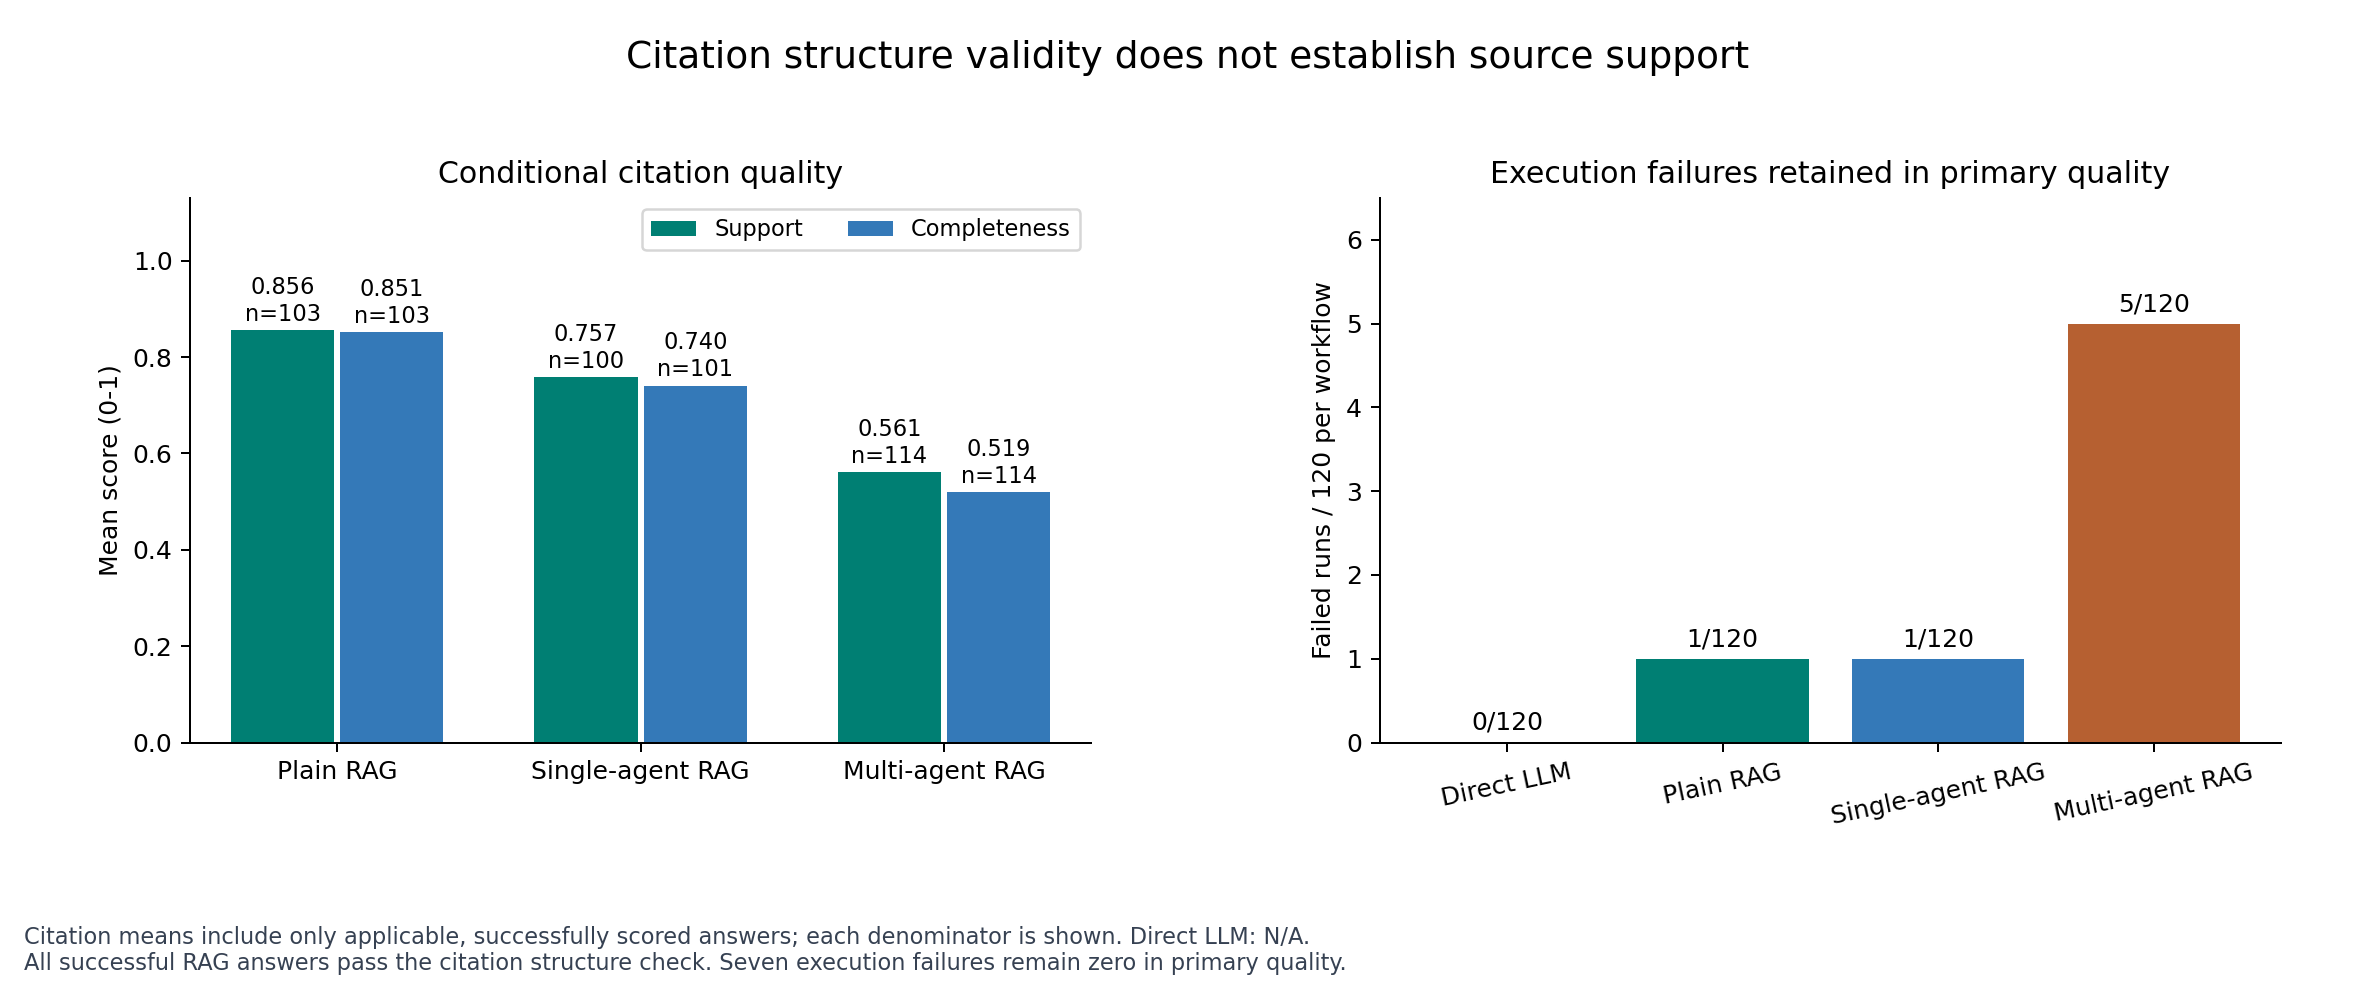

Exported 3 PNG/SVG figure sets, local PDFs under artifacts/evaluation/heldout-analysis/figures/, analysis-tables.json and question-means.csv.


In [6]:
from IPython.display import Image, display
import matplotlib.pyplot as plt
write_tables(tables)
figures = render_figures(tables)
names = ['workflow-comparison', 'paired-quality', 'citations-and-failures']
for figure, name in zip(figures, names):
    figure_path = ROOT / 'docs/evaluation/heldout-test/figures' / f'{name}.png'
    display(Image(filename=str(figure_path)))
    plt.close(figure)
print('Exported 3 PNG/SVG figure sets, local PDFs under artifacts/evaluation/heldout-analysis/figures/, analysis-tables.json and question-means.csv.')


## 7. Inspect retained failures and uncertain answers

These cases were selected **after observing results** to illustrate different failure mechanisms; they are not a prevalence estimate or an additional benchmark. The linked failure guide explains each case against its exact saved answer and adjudication. Unit identifiers encode repeat and line number, starting at 1.


In [7]:
by_unit = {row['unit']: row for row in analysis['unit_scores']}
selected = ['r0-answer-118', 'r0-answer-145', 'r0-answer-143', 'r0-answer-007', 'r0-answer-157', 'r0-answer-043', 'r0-answer-138']
print(f"{'Unit':<15} {'Case':<15} {'Workflow':<23} {'Quality':>7} {'Status'}")
for unit in selected:
    trace, row = traces[unit], by_unit[unit]
    print(f"{unit:<15} {trace.case_id:<15} {trace.variant.value:<23} {row['primary_quality']:7.3f} {trace.error_code or trace.status}")
print('Each answer, retrieved passage, original judgment and AI correction remains in the public packet.')


Unit            Case            Workflow                Quality Status
r0-answer-118   REAL-TEST-005   baseline_llm              0.000 success
r0-answer-145   REAL-TEST-014   single_agent_rag          0.500 success
r0-answer-143   REAL-TEST-031   llm_rag                   0.000 success
r0-answer-007   REAL-TEST-004   multi_agent_rag           0.500 success
r0-answer-157   REAL-TEST-038   multi_agent_rag           0.333 success
r0-answer-043   REAL-TEST-006   single_agent_rag          0.000 invalid_citation
r0-answer-138   REAL-TEST-035   multi_agent_rag           0.000 invalid_citation
Each answer, retrieved passage, original judgment and AI correction remains in the public packet.


## Interpretation and next decisions

This small documentation benchmark favors plain RAG overall. Multi-agent RAG exceeds single-agent RAG on the prespecified correctness statistic after AI source review, with much greater median successful latency and lower conditional citation support. The eight-family bootstrap interval describes exploratory uncertainty for this dataset; it does not establish general superiority.

Keep these observations as a fixed baseline. Follow-up work can investigate citation entailment, retrieval misses, version confusion and bounded workflow overhead using development data and new evaluation sets. Do not retune on these held-out answers and present a rerun as an untouched test.

Remaining limits include AI-authored references, correlated reviewer errors, no human validation, possible pretraining exposure to public docs, serial execution on one machine and incomplete billing information. See `docs/evaluation/heldout-test/FAILURE-CASES.md` and `REPRODUCE.md` for evidence and exact commands.
